İlk eğitim adımları. Modeli rastgele başlat ve ilk loss'u ölç, ln(50257) ≈ 10.8 ile karşılaştır. Neden bu değere yakın çıkmalı, kendi cümlelerinle yaz. Sonra tek bir batch'i ezberlet: aynı batch'te birkaç yüz adım eğit, loss sıfıra yaklaşmalı. Bu test neden işe yarıyor? (0:45:50 - 1:02:00)


### 1. GPT-2 Model Mimarisi (Eğitim Modu)
Modeli sıfırdan eğitilebilir halde kuruyoruz. İleri geçişte (`forward`) hedef etiketler (`targets`) verildiğinde otomatik olarak `cross_entropy` kaybı hesaplanır.

In [ ]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import math
from dataclasses import dataclass
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import tiktoken

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12
    n_head: int = 12
    n_embd: int = 768

class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                     .view(1, 1, config.block_size, config.block_size))

    def forward(self, x):
        B, T, C = x.size()
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        head_size = C // self.n_head
        k = k.view(B, T, self.n_head, head_size).transpose(1, 2)
        q = q.view(B, T, self.n_head, head_size).transpose(1, 2)
        v = v.view(B, T, self.n_head, head_size).transpose(1, 2)
        
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(head_size))
        att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.c_proj(y)

class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate='tanh')
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)

    def forward(self, x):
        return self.c_proj(self.gelu(self.c_fc(x)))

class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.transformer.wte.weight = self.lm_head.weight

    def forward(self, idx, targets=None):
        B, T = idx.size()
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        pos_emb = self.transformer.wpe(pos)
        tok_emb = self.transformer.wte(idx)
        x = tok_emb + pos_emb
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss
 

GPT mimarisi hazırlandı.


In [10]:
-math.log(1/50257)

10.82490511970208

In [2]:
# Cihaz seçimi ve rastgele tohum (seed)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Modeli RASTGELE ağırlıklarla başlatıyoruz
model = GPT(GPTConfig()).to(device)
model.train()

# Shakespeare metninden ilk batch'i hazırlıyoruz
enc = tiktoken.get_encoding('gpt2')
input_path = 'input.txt' if os.path.exists('input.txt') else 'hafta-10/input.txt'
with open(input_path, 'r', encoding='utf-8') as f:
    text = f.read()

# Örnek batch oluşturma
tokens = enc.encode(text[:1000])
T = 40
buf = torch.tensor(tokens[:T+1])
x = buf[:-1].view(1, T).to(device)
y = buf[1:].view(1, T).to(device)

# Modelin ilk adımdaki kaybını ölçüyoruz
with torch.no_grad():
    logits, initial_loss = model(x, y)

theoretical_loss = math.log(50257)

print("=" * 65)
print(f"Sözlük Boyutu (V)             : 50,257")
print(f"Teorik Kayıp (ln(50257))       : {theoretical_loss:.6f}")
print(f"Modelin Ölçülen İlk Kaybı     : {initial_loss.item():.6f}")
print(f"Fark (Ölçülen - Teorik)       : {abs(initial_loss.item() - theoretical_loss):.6f}")
print("=" * 65)


Sözlük Boyutu (V)             : 50,257
Teorik Kayıp (ln(50257))       : 10.824905
Modelin Ölçülen İlk Kaybı     : 10.962744
Fark (Ölçülen - Teorik)       : 0.137839


### 4. Tek Bir Batch'i Ezberletme (Overfitting a Single Batch)
Şimdi derin öğrenmede en önemli testlerden biri olan **tek bir batch'i ezberletme** deneyini yapıyoruz:
- Sabit tek bir batch ($x, y$) üzerinde modeli AdamW optimizörü ile ardışık adımlarla eğitiyoruz.
- Model her adımda sadece bu veriyi gördüğü için kaybın (loss) hızla sıfıra yaklaşması beklenir.


In [11]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.0)

num_steps = 70
losses = []

print(f"{'Adım (Step)':<15} | {'Loss Değeri':<20}")
print("-" * 38)

for step in range(num_steps):
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    
    losses.append(loss.item())
    
    if step % 10 == 0 or step == num_steps - 1:
        print(f"Adım {step:<10} | {loss.item():<20.6f}")


Adım (Step)     | Loss Değeri         
--------------------------------------
Adım 0          | 0.000392            
Adım 10         | 0.009869            
Adım 20         | 0.002206            
Adım 30         | 0.000752            
Adım 40         | 0.000366            
Adım 50         | 0.000219            
Adım 60         | 0.000157            
Adım 69         | 0.000128            


### 5. Kayıp (Loss) Düşüş Grafiği
Eğitim boyunca kaybın 10.82 teorik değerinden başlayıp nasıl sıfıra yaklaştığını çizdiriyoruz.

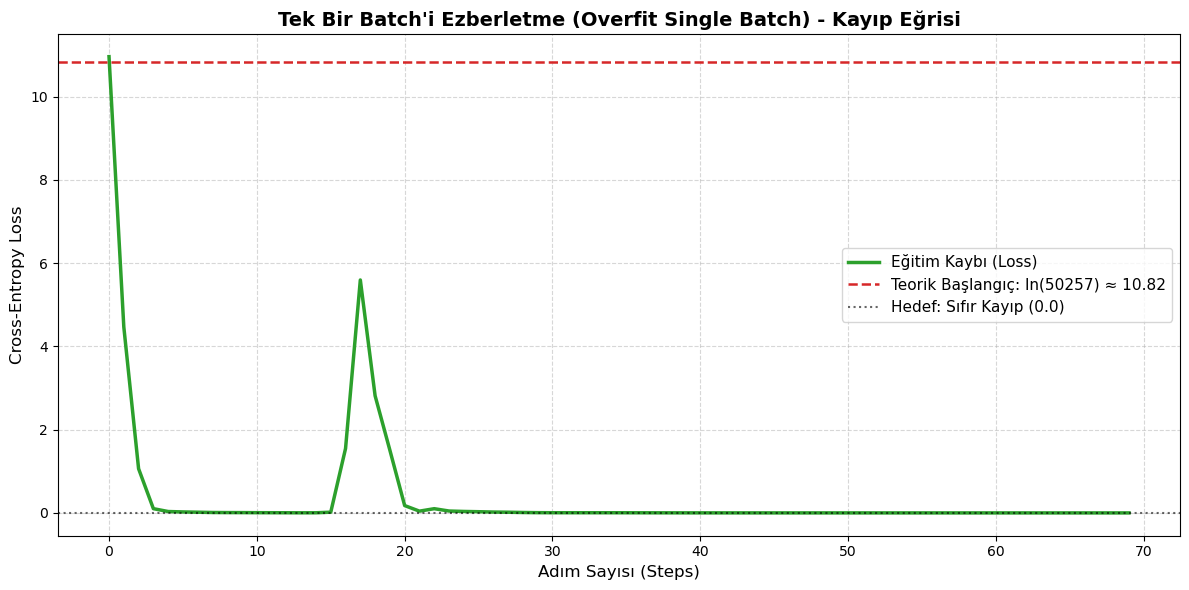

In [4]:
plt.figure(figsize=(12, 6))
plt.plot(range(num_steps), losses, color='#2ca02c', linewidth=2.5, label='Eğitim Kaybı (Loss)')
plt.axhline(y=theoretical_loss, color='#d62728', linestyle='--', linewidth=1.8, label=f'Teorik Başlangıç: ln(50257) ≈ {theoretical_loss:.2f}')
plt.axhline(y=0.0, color='black', linestyle=':', alpha=0.6, label='Hedef: Sıfır Kayıp (0.0)')

plt.title("Tek Bir Batch'i Ezberletme (Overfit Single Batch) - Kayıp Eğrisi", fontsize=14, fontweight='bold')
plt.xlabel("Adım Sayısı (Steps)", fontsize=12)
plt.ylabel("Cross-Entropy Loss", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()
